In [1]:
import json
from pathlib import Path

# Find all saved raw JSON files
raw_folder = Path("../data/raw")
json_files = list(raw_folder.glob("*/*.json"))

print(f"Number of JSON files found: {len(json_files)}")

# Open the first file
with json_files[0].open("r", encoding="utf-8") as file:
    payload = json.load(file)

# Inspect the main sections
print(payload.keys())

Number of JSON files found: 14
dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])


In [2]:
# Inspect the hourly weather data
payload["hourly"].keys()

dict_keys(['time', 'temperature_2m', 'relative_humidity_2m', 'apparent_temperature', 'precipitation', 'wind_speed_10m', 'weather_code'])

In [3]:
# Inspect the units
payload["hourly_units"]

{'time': 'iso8601',
 'temperature_2m': '°C',
 'relative_humidity_2m': '%',
 'apparent_temperature': '°C',
 'precipitation': 'mm',
 'wind_speed_10m': 'km/h',
 'weather_code': 'wmo code'}

In [4]:
import pandas as pd

df_london = pd.DataFrame(payload["hourly"])

df_london["city"] = "London"
df_london["latitude"] = payload["latitude"]
df_london["longitude"] = payload["longitude"]

df_london.head()

,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,city,latitude,longitude
0,2026-11-16T00:00,5.4,88,1.4,0.0,17.3,2,London,52.488224,-1.909378
1,2026-11-16T01:00,4.7,87,1.0,0.0,14.0,1,London,52.488224,-1.909378
2,2026-11-16T02:00,4.3,86,0.7,0.0,13.0,1,London,52.488224,-1.909378
3,2026-11-16T03:00,3.8,82,-0.1,0.0,13.3,0,London,52.488224,-1.909378
4,2026-11-16T04:00,3.2,82,-0.8,0.0,13.3,2,London,52.488224,-1.909378


In [5]:
def flatten(payload: dict, city_name: str) -> pd.DataFrame:
    """
    Convert one city's hourly weather JSON into a DataFrame.
    """

    df = pd.DataFrame(payload["hourly"])

    df["city"] = city_name
    df["latitude"] = payload["latitude"]
    df["longitude"] = payload["longitude"]

    return df

In [6]:
df_london = flatten(payload, "London")

df_london.head()

,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,city,latitude,longitude
0,2026-11-16T00:00,5.4,88,1.4,0.0,17.3,2,London,52.488224,-1.909378
1,2026-11-16T01:00,4.7,87,1.0,0.0,14.0,1,London,52.488224,-1.909378
2,2026-11-16T02:00,4.3,86,0.7,0.0,13.0,1,London,52.488224,-1.909378
3,2026-11-16T03:00,3.8,82,-0.1,0.0,13.3,0,London,52.488224,-1.909378
4,2026-11-16T04:00,3.2,82,-0.8,0.0,13.3,2,London,52.488224,-1.909378


In [7]:
# Find all JSON files in the raw data folders
json_files = list(raw_folder.glob("*/*.json"))

# Keep the latest file for each city
latest_files = {}

for file_path in json_files:
    city_name = file_path.name.split("_")[0]

    if (
        city_name not in latest_files
        or file_path.stat().st_mtime
        > latest_files[city_name].stat().st_mtime
    ):
        latest_files[city_name] = file_path

print("Latest files selected:")

for city, file_path in latest_files.items():
    print(city, ":", file_path)

Latest files selected:
birmingham : ..\data\raw\2026-11-18\birmingham_20261118T002555.json
cardiff : ..\data\raw\2026-11-18\cardiff_20261118T002556.json
edinburgh : ..\data\raw\2026-11-18\edinburgh_20261118T002556.json
london : ..\data\raw\2026-11-18\london_20261118T002555.json
manchester : ..\data\raw\2026-11-18\manchester_20261118T002555.json


In [8]:
# Load and flatten the latest file for each city
city_dfs = []

for city_name, file_path in latest_files.items():

    with file_path.open("r", encoding="utf-8") as file:
        payload = json.load(file)

    city_df = flatten(payload, city_name.title())

    city_dfs.append(city_df)

# Combine all cities into one DataFrame
df = pd.concat(city_dfs, ignore_index=True)

print("Combined DataFrame created!")

Combined DataFrame created!


In [9]:
df.head()

,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,city,latitude,longitude
0,2026-11-17T00:00,2.5,95,-2.0,0.8,18.7,53,Birmingham,52.488224,-1.909378
1,2026-11-17T01:00,2.8,96,-1.7,2.6,19.1,63,Birmingham,52.488224,-1.909378
2,2026-11-17T02:00,2.9,96,-1.7,4.0,20.2,63,Birmingham,52.488224,-1.909378
3,2026-11-17T03:00,3.0,96,-1.3,4.3,17.3,63,Birmingham,52.488224,-1.909378
4,2026-11-17T04:00,3.0,97,-0.8,0.9,14.0,53,Birmingham,52.488224,-1.909378


In [10]:
df["city"].unique()

<StringArray>
['Birmingham', 'Cardiff', 'Edinburgh', 'London', 'Manchester']
Length: 5, dtype: str

In [11]:
df["city"].value_counts()

city
Birmingham    48
Cardiff       48
Edinburgh     48
London        48
Manchester    48
Name: count, dtype: int64

In [12]:
df.shape

(240, 10)

In [13]:
df.dtypes

time                        str
temperature_2m          float64
relative_humidity_2m      int64
apparent_temperature    float64
precipitation           float64
wind_speed_10m          float64
weather_code              int64
city                        str
latitude                float64
longitude               float64
dtype: object

In [14]:
df.head()

,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,city,latitude,longitude
0,2026-11-17T00:00,2.5,95,-2.0,0.8,18.7,53,Birmingham,52.488224,-1.909378
1,2026-11-17T01:00,2.8,96,-1.7,2.6,19.1,63,Birmingham,52.488224,-1.909378
2,2026-11-17T02:00,2.9,96,-1.7,4.0,20.2,63,Birmingham,52.488224,-1.909378
3,2026-11-17T03:00,3.0,96,-1.3,4.3,17.3,63,Birmingham,52.488224,-1.909378
4,2026-11-17T04:00,3.0,97,-0.8,0.9,14.0,53,Birmingham,52.488224,-1.909378


In [15]:
df.isna().sum()

time                    0
temperature_2m          0
relative_humidity_2m    0
apparent_temperature    0
precipitation           0
wind_speed_10m          0
weather_code            0
city                    0
latitude                0
longitude               0
dtype: int64

In [16]:
df.describe()

,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,latitude,longitude
count,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000
mean,7.911667,87.316667,5.184167,0.404167,11.921250,28.075000,52.983542,-2.133569
std,2.534917,7.225574,2.731560,0.840093,5.631086,25.742095,1.663127,1.128787
min,2.500000,59.000000,-2.000000,0.000000,2.200000,0.000000,51.480080,-3.206848
25%,6.000000,82.000000,3.400000,0.000000,6.800000,3.000000,51.511470,-3.192810
50%,7.900000,88.000000,5.750000,0.050000,11.900000,27.000000,52.488224,-2.228027
75%,9.900000,93.000000,7.325000,0.400000,16.200000,51.000000,53.478767,-1.909378
max,13.500000,99.000000,9.700000,5.100000,28.400000,63.000000,55.959167,-0.130783


In [17]:
df.duplicated(subset=["city", "time"]).sum()

np.int64(0)

In [18]:
df[df.duplicated(subset=["city", "time"], keep=False)].sort_values(
    ["city", "time"]
)

,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,city,latitude,longitude


In [19]:
sorted(df["weather_code"].dropna().unique())

[np.int64(0),
 np.int64(1),
 np.int64(2),
 np.int64(3),
 np.int64(51),
 np.int64(53),
 np.int64(55),
 np.int64(61),
 np.int64(63)]

In [20]:
df["time"] = pd.to_datetime(df["time"])

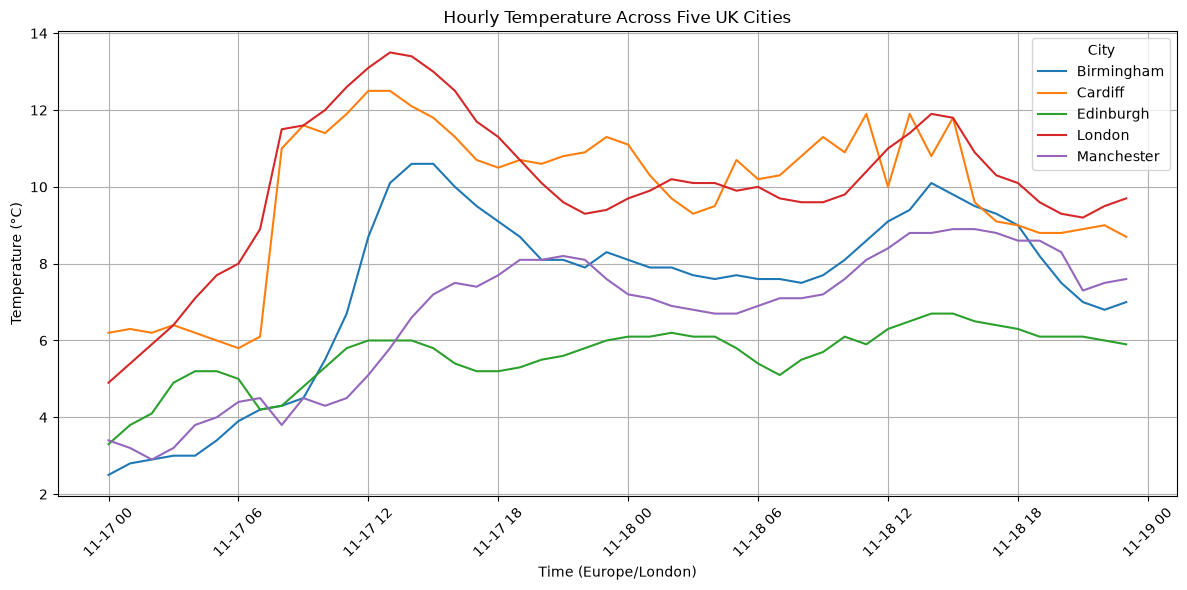

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for city in df["city"].unique():
    city_data = df[df["city"] == city].sort_values("time")

    plt.plot(
        city_data["time"],
        city_data["temperature_2m"],
        label=city
    )

plt.title("Hourly Temperature Across Five UK Cities")
plt.xlabel("Time (Europe/London)")
plt.ylabel("Temperature (°C)")
plt.legend(title="City")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [22]:
df.duplicated(subset=["city", "time"]).sum()

np.int64(0)

In [23]:
df.shape

(240, 10)

## Five Findings

1. **Data volume:** The combined DataFrame contains **240 rows and 10 columns**, covering five UK cities: Birmingham, Cardiff, Edinburgh, London and Manchester. Each city has 48 hourly weather records.

2. **Data types:** The `time` column was initially loaded as text (`str`). I converted it to datetime using `pd.to_datetime()` so that records can be sorted chronologically and used correctly for time-series analysis and plotting. The remaining columns have appropriate numerical or string data types.

3. **Missing values:** The profiling found **0 missing values across all 10 columns**. All 240 records contain complete values for timestamps, weather measurements, city names and geographical coordinates.

4. **Duplicate records:** There are **0 duplicate records** based on the combination of `city` and `time`. This confirms that each city has only one record for each hourly timestamp in the combined DataFrame.

5. **Weather values:** The observed temperature range is **2.5°C to 13.5°C**, with an average temperature of approximately **7.91°C** across all five cities. The distinct weather codes include **0, 1, 2, 3, 51, 53, 55, 61 and 63**. These represent clear sky, mainly clear, partly cloudy, overcast, different intensities of drizzle and slight to moderate rain, according to WMO weather interpretation codes.